In [1]:
import os 
import warnings
warnings.filterwarnings("ignore")
import autogen
from autogen import ConversableAgent
from autogen.agentchat.contrib.multimodal_conversable_agent import MultimodalConversableAgent
from IPython.display import Markdown, display, Image

In [2]:
from getpass import getpass
import os

os.environ["OPENAI_API_KEY"] = getpass("Enter OpenAI API Key: ")

In [3]:
# configuration for LLM
config_list_1 = {
    "config_list": [{"model": "gpt-4o", "temperature": 0.3}]
}

In [4]:
bill_processing_agent = MultimodalConversableAgent(
    "Bill_Processing_Agent",
    system_message = """
    Given an input image, extract data from the uploaded bill image and organize expenses into categories
    (e.g., groceries, dining, utilities, shopping, and entertainment). Also return the total amount spent.
    """,
    llm_config=config_list_1,
    human_input_mode="NEVER",
)

expense_summarization_agent = ConversableAgent(
    "Expense_Summarization_Agent",
    system_message = """
    Analyze the extracted expenses and provide a breakdown of total spending per category.
    Highlight any unusual or high spending trends.
    Return a summary of spending trends, showing which category has the highest expenditure.
    """,
    llm_config=config_list_1,
    human_input_mode="NEVER",
)

In [5]:
user_proxy = autogen.UserProxyAgent(
    name="User_proxy",
    system_message="""
    You are assisting in analyzing uploaded bill images and coordinating among agents to organize the expenses.
    If the input contains URLs, fetch and incorporate relevant details.
    """,
    human_input_mode="TERMINATE",  # Try between ALWAYS, NEVER, and TERMINATE
    max_consecutive_auto_reply=0,
    code_execution_config={
        "use_docker": False  # Set to True if Docker is available
    },
)

In [9]:
group_meet = autogen.GroupChat(
    agents=[user_proxy,bill_processing_agent, expense_summarization_agent],
    messages=[],
    max_round=4,
    speaker_selection_method= "round_robin",
    select_speaker_auto_llm_config = config_list_1
)
group_manager = autogen.GroupChatManager(
    groupchat=group_meet,
)

In [10]:
meeting = user_proxy.initiate_chat(
    group_manager,
    message="""
    Analyze the bill image and extract any unusual or high spending trends.
    Return a summary of spending trends, showing which category has the highest expenditure.
    <img cash_receipt.avif>
    """,
    summary_method="last_msg",
)

User_proxy (to chat_manager):


    Analyze the bill image and extract any unusual or high spending trends.
    Return a summary of spending trends, showing which category has the highest expenditure.
    <img cash_receipt.avif>
    

--------------------------------------------------------------------------------

Next speaker: Bill_Processing_Agent

Bill_Processing_Agent (to chat_manager):

Based on the receipts in the image, here is a summary of spending trends:

### Categories and Expenditures:
1. **Dining/Shopping:**
   - Multiple entries with items like "Lorem ipsum," "Eud tempor," "Duis aute irure," etc.
   - Costs range from $2.45 to $79.80.

2. **Hotel:**
   - Charges for room and services, with totals like $100.45 and $126.90.

### Highest Expenditure:
- **Dining/Shopping** has the highest individual item costs, with some items reaching up to $79.80.

### Unusual or High Spending Trends:
- The presence of multiple high-cost items in the dining/shopping category suggests a tre

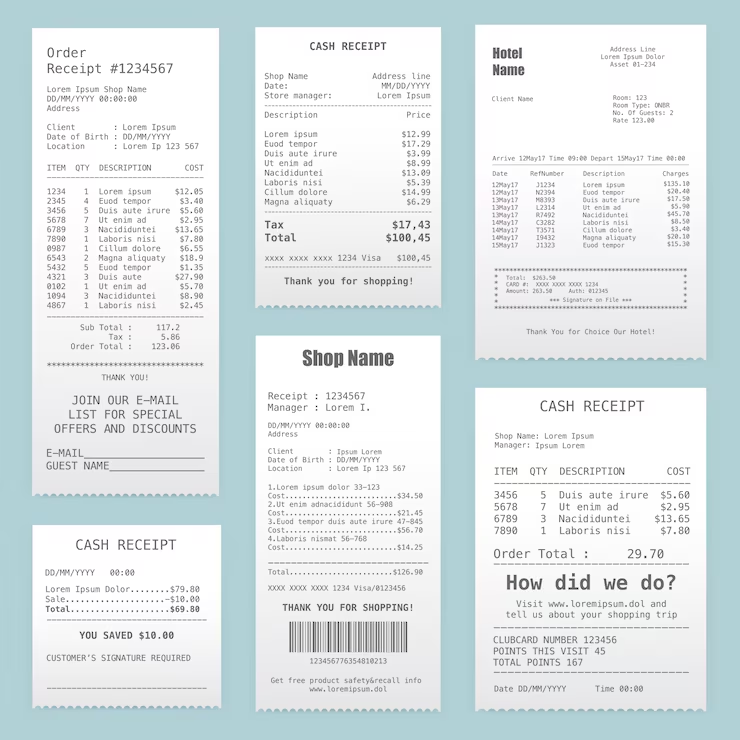

## User_proxy

## Bill_Processing_Agent

Based on the receipts in the image, here is a summary of spending trends:

### Categories and Expenditures:
1. **Dining/Shopping:**
   - Multiple entries with items like "Lorem ipsum," "Eud tempor," "Duis aute irure," etc.
   - Costs range from $2.45 to $79.80.

2. **Hotel:**
   - Charges for room and services, with totals like $100.45 and $126.90.

### Highest Expenditure:
- **Dining/Shopping** has the highest individual item costs, with some items reaching up to $79.80.

### Unusual or High Spending Trends:
- The presence of multiple high-cost items in the dining/shopping category suggests a trend of significant spending in this area.
- Hotel expenses are also notable but are generally expected for accommodation.

Overall, the dining/shopping category shows the highest expenditure, with several high-cost items contributing to the total.

## Expense_Summarization_Agent

Based on the analysis of the bill image, here is a breakdown of total spending per category and notable spending trends:

### Categories and Expenditures:
1. **Dining/Shopping:**
   - Multiple entries with varying costs, such as:
     - "Lorem ipsum" - $79.80
     - "Eud tempor" - $45.60
     - "Duis aute irure" - $2.45
   - This category includes both low and high-cost items, with a significant total expenditure.

2. **Hotel:**
   - Charges for room and services, including:
     - Room charge - $100.45
     - Additional services - $126.90
   - These expenses are typical for accommodation but contribute significantly to overall spending.

### Highest Expenditure:
- **Dining/Shopping** emerges as the category with the highest expenditure due to multiple high-cost items.

### Unusual or High Spending Trends:
- The dining/shopping category shows a trend of high spending, with several items costing significantly more than others.
- The presence of multiple high-cost items suggests a pattern of substantial spending in this area.
- Hotel expenses are also notable, but they are generally expected for accommodation purposes.

In summary, the dining/shopping category has the highest expenditure, with several high-cost items contributing to the overall spending trend.

In [11]:
from PIL import Image as PILImage

agent_name_to_find = ["User_proxy", "Bill_Processing_Agent", "Expense_Summarization_Agent"]

display(PILImage.open("cash_receipt.avif"))
for agent_name in agent_name_to_find:

    # Iterate through the dictionary to find the last conversation for the specified agent
    for agent, interactions in group_manager.chat_messages.items():
        # Filter interactions by agent name
        filtered_interactions = [i for i in interactions if i.get("name") == agent_name]
        if filtered_interactions:
            # Print the last conversation's content
            # print(filtered_interactions[-1]["content"])
            display(Markdown('## ' + agent_name))
            display(Markdown(filtered_interactions[-1]["content"]))
            break
    else:
        print("Agent not found or no interactions available.")
